In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

df_org = pd.read_csv("./house_train.csv")
df = df_org.copy()
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [30]:
print(df.shape)
print(df.dtypes.value_counts())
isnull_series = df.isnull().sum()
print(isnull_series[isnull_series>0].sort_values(ascending = False))

(1460, 81)
object     43
int64      35
float64     3
dtype: int64
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64


In [31]:
df["FireplaceQu"]

0       NaN
1        TA
2        TA
3        Gd
4        TA
       ... 
1455     TA
1456     TA
1457     Gd
1458    NaN
1459    NaN
Name: FireplaceQu, Length: 1460, dtype: object

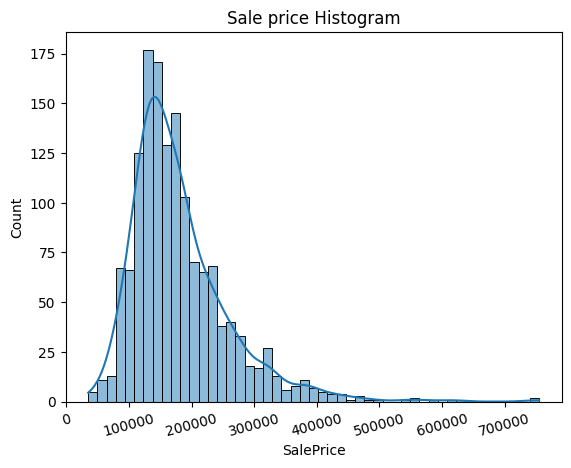

In [32]:
plt.title("Sale price Histogram")
plt.xticks(rotation = 15)
sns.histplot(df [ "SalePrice"], kde = True)
plt.show()

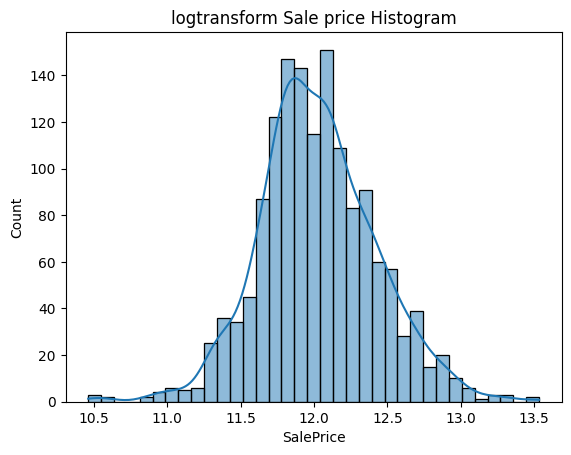

In [33]:
plt.title("logtransform Sale price Histogram")
log_SalePrice = np.log1p(df["SalePrice"])
sns.histplot(log_SalePrice, kde = True)
plt.show()

In [34]:
org_SalePrice = df["SalePrice"]
df["SalePrice"] = np.log1p(df["SalePrice"])####영기 대문자 오타

df.drop(["Id" , "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu"],axis = 1, inplace = True)

df.fillna(df.mean(), inplace=True)

null_column_count = df.isnull().sum()[df.isnull().sum() > 0]
print(df.dtypes[null_column_count.index])

MasVnrType      object
BsmtQual        object
BsmtCond        object
BsmtExposure    object
BsmtFinType1    object
BsmtFinType2    object
Electrical      object
GarageType      object
GarageFinish    object
GarageQual      object
GarageCond      object
dtype: object


In [35]:
print(df.shape)
df_ohe = pd.get_dummies(df)
print(df_ohe.shape)

(1460, 75)
(1460, 271)


In [36]:
null_column_count = df_ohe.isnull().sum()[df_ohe.isnull().sum()>0]

print(df_ohe.dtypes[null_column_count.index])

Series([], dtype: object)


In [37]:
def get_rmse(model) : 
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test,pred)
    rmse = np.sqrt(mse)
    print(model.__class__.__name__, np.round(rmse,3))
    return rmse

def get_rmses(models):
    rmses = []
    for model in models:
        rmse = get_rmse(model)
        rmses.append(rmse)

    return rmses

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error

y_target = df_ohe["SalePrice"]
X_features = df_ohe.drop(["SalePrice"],axis = 1 , inplace= False)

X_train , X_test , y_train , y_test  = train_test_split(X_features, y_target, test_size= 0.2, random_state=156 )

lr_reg = LinearRegression()
lr_reg.fit(X_train,y_train)

ridge_reg = Ridge()
ridge_reg.fit(X_train, y_train)

lasso_reg = Lasso()
lasso_reg.fit(X_train, y_train)

models = [lr_reg , ridge_reg , lasso_reg]
get_rmses(models)

LinearRegression 0.132
Ridge 0.128
Lasso 0.176


[0.13189576579154688, 0.1275084633405301, 0.17628250556471403]

In [39]:
def get_top_bottom_coef(model):
    coef = pd.Series(model.coef_, index = X_features.columns)
    coef_high = coef.sort_values(ascending= False).head(10)
    coef_low = coef.sort_values(ascending= False).tail(10)
    return coef_high , coef_low

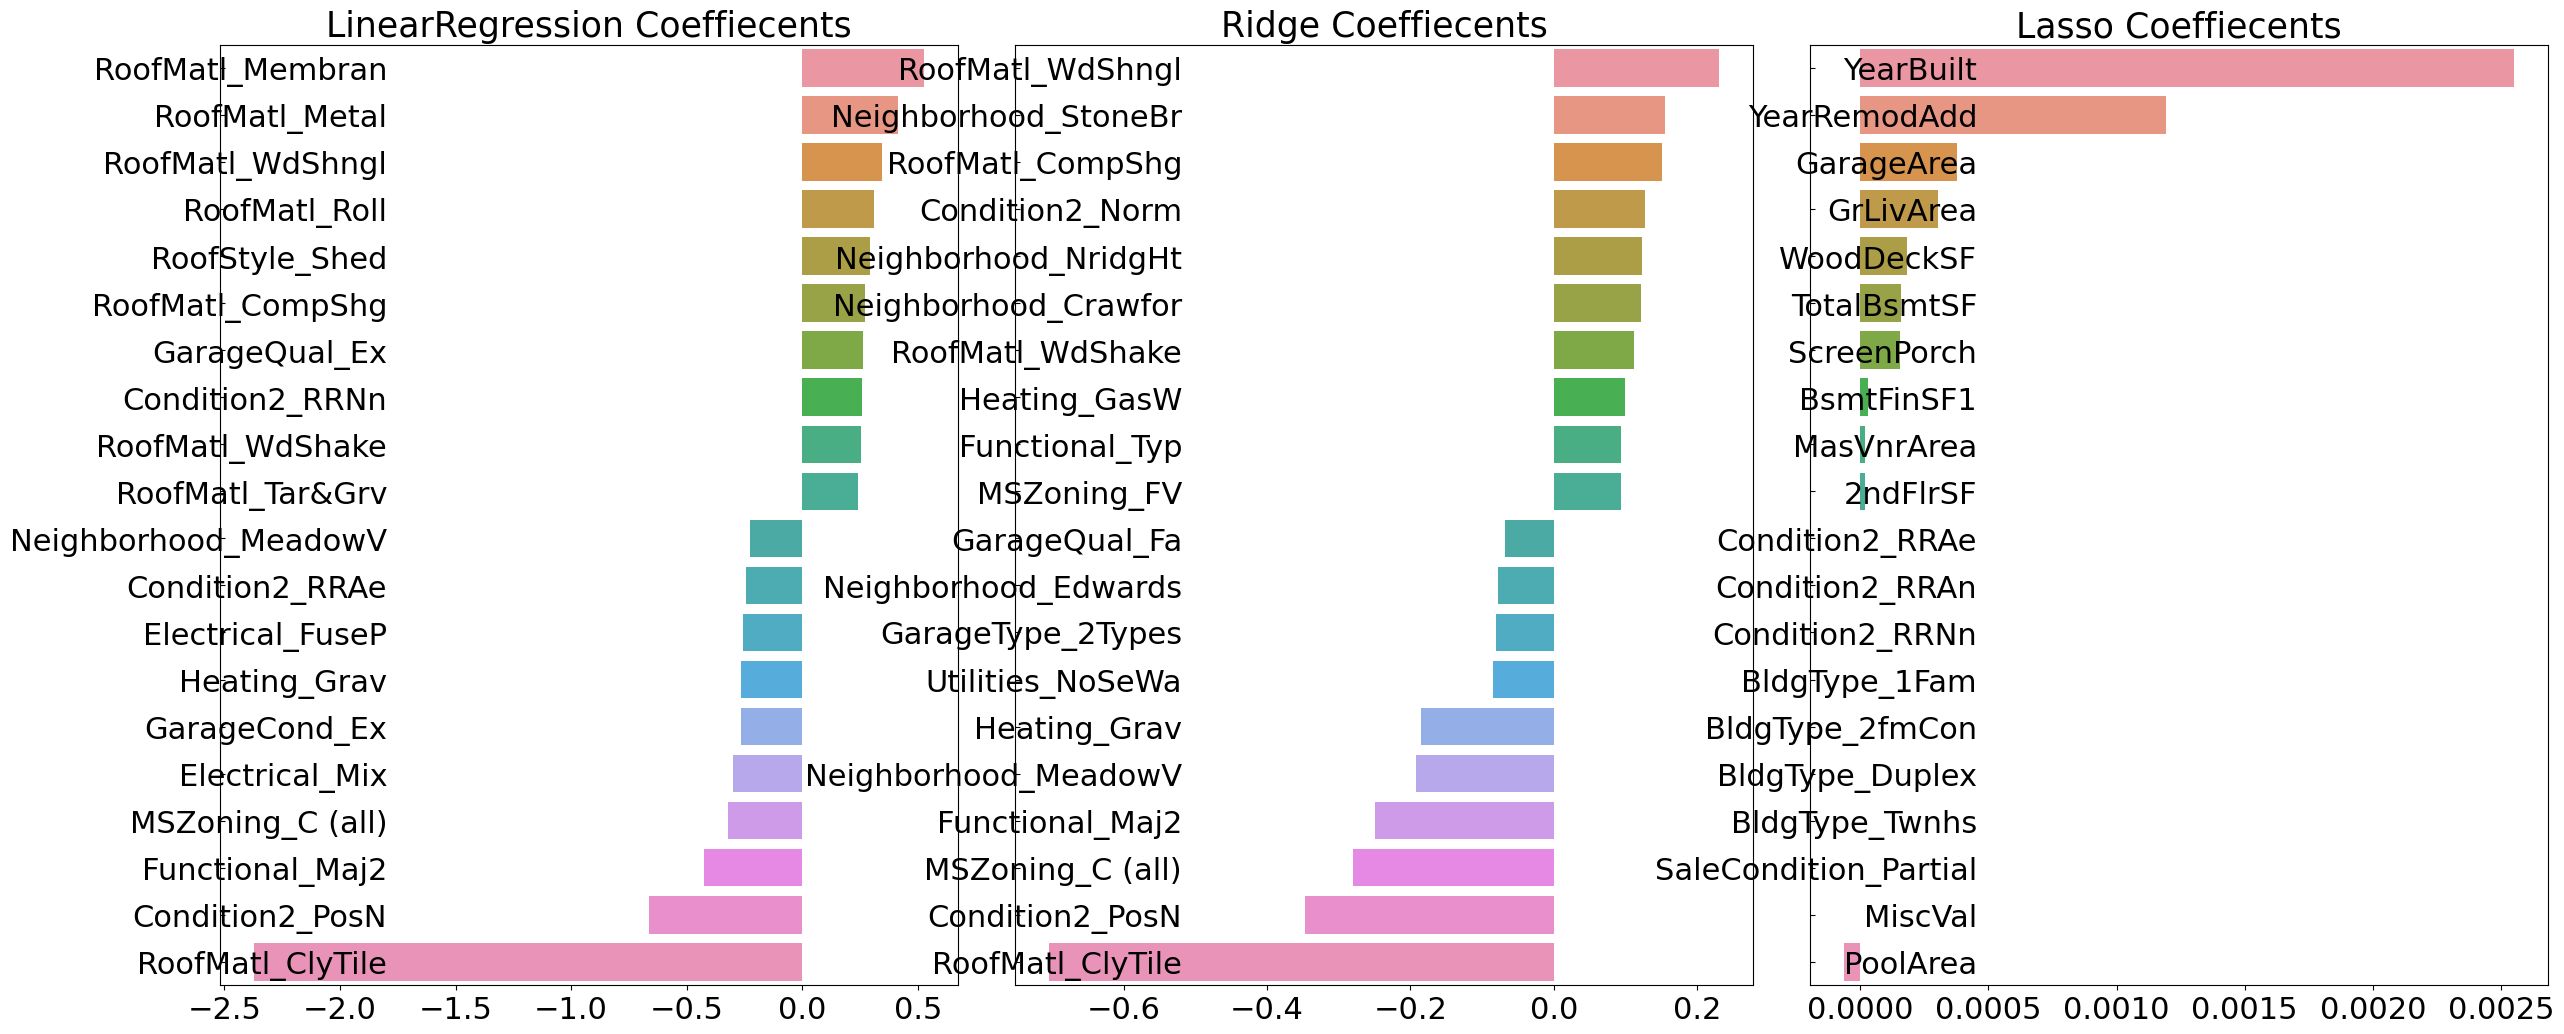

In [40]:
def visualize_coef(models):
    fig, axs = plt.subplots(figsize = (24, 10), nrows = 1, ncols = 3)
    fig.tight_layout()
    for i_num, model in enumerate(models):
        coef_high, coef_low = get_top_bottom_coef(model)
        coef_concat = pd.concat([coef_high, coef_low])
        axs[i_num].set_title(model.__class__.__name__+' Coeffiecents',
                             size = 25)
        axs[i_num].tick_params(axis = 'y', direction = 'in', pad = -120)
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x = coef_concat.values, y = coef_concat.index,
                    ax = axs[i_num])

model = [lr_reg, ridge_reg, lasso_reg]
visualize_coef(models)

In [41]:
from sklearn.model_selection import cross_val_score

def get_avg_rmse_cv(models):
    for model in models :
        rmse_list = np.sqrt(-cross_val_score(model,X_features,y_target,scoring= "neg_mean_squared_error",cv = 5))    
        rmse_avg = np.mean(rmse_list)
        print(model.__class__.__name__, np.round(rmse_list, 3))
        print(model.__class__.__name__, np.round(rmse_avg, 3))

models = [lr_reg, ridge_reg, lasso_reg]
get_avg_rmse_cv(models)

LinearRegression [1.350000e-01 6.918263e+03 1.680000e-01 1.110000e-01 1.980000e-01]
LinearRegression 1383.775
Ridge [0.117 0.154 0.142 0.117 0.189]
Ridge 0.144
Lasso [0.161 0.204 0.177 0.181 0.265]
Lasso 0.198


In [42]:
from sklearn.model_selection import GridSearchCV

def print_best_params(model , params):
    grid_model = GridSearchCV(model, param_grid= params,
                              scoring="neg_mean_squared_error", cv = 5)

    grid_model. fit(X_features, y_target)
    rsme = np.sqrt(-1 * grid_model.best_score_)
    print(model.__class__.__name__,np.round(rsme,4) ,grid_model.best_params_)
    return grid_model.best_estimator_

ridge_params = {"alpha" : [0.05 , 0.1 , 1 ,5 ,8, 10, 12, 15 ,20]}
lasso_params = { "alpha" : [0.001, 0.005, 0.008, 0.03, 0.05, 0.1, 0.5, 1, 5]}
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 0.1418 {'alpha': 12}
Lasso 0.142 {'alpha': 0.001}


LinearRegression 0.132
Ridge 0.124
Lasso 0.12


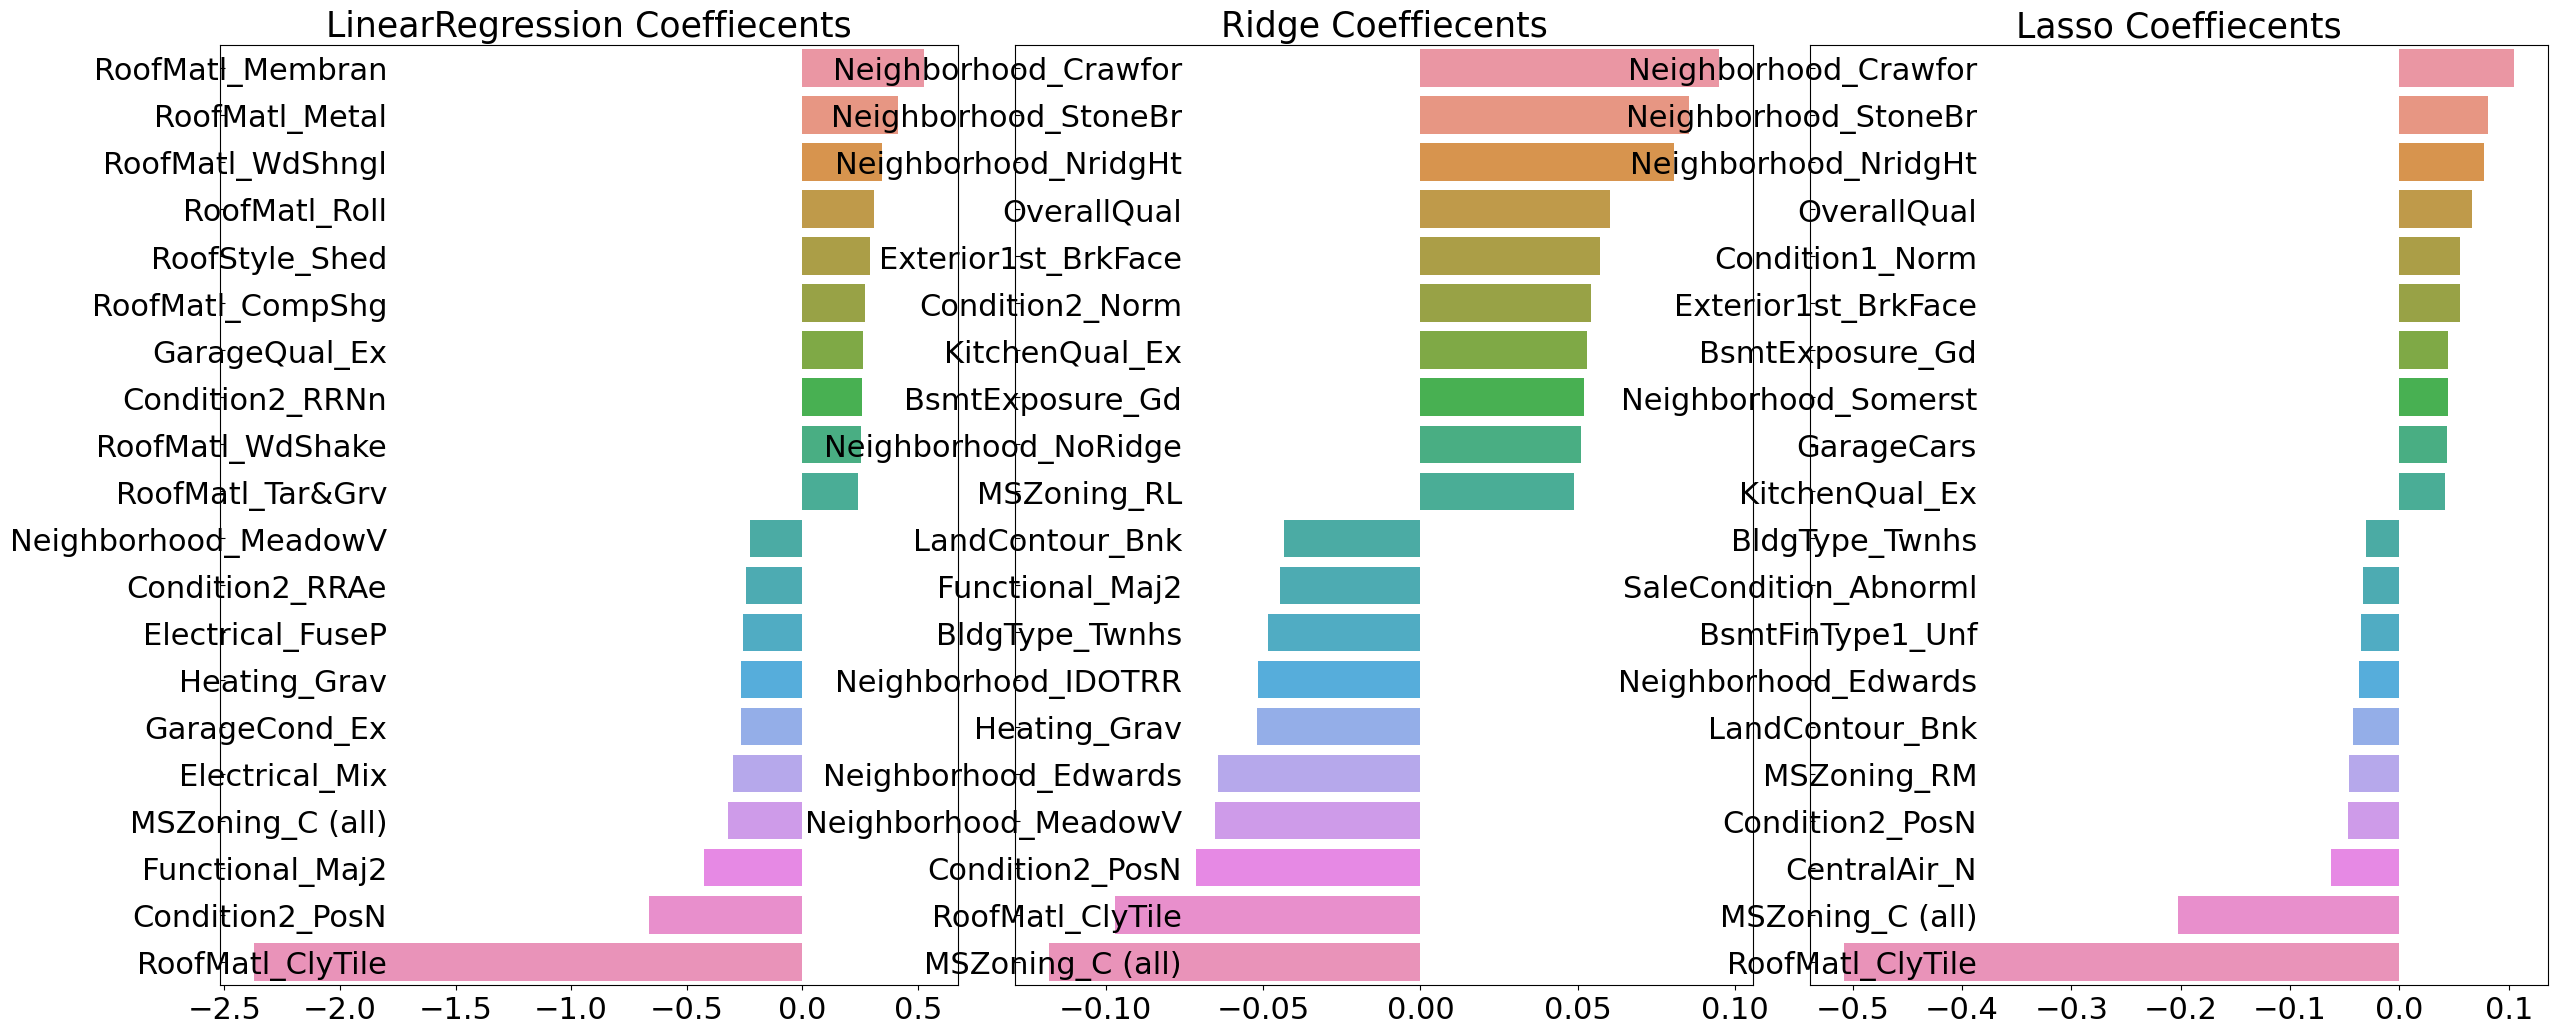

In [43]:
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha = 12)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha = 0.001)
lasso_reg.fit(X_train, y_train)

models = [lr_reg,ridge_reg,lasso_reg]

get_rmses(models)
visualize_coef(models)

In [44]:
from scipy.stats import skew

features_index = df.dtypes[df.dtypes != "object"].index
skew_feature = df[features_index].apply(lambda x : skew(x))
skew_feature_top = skew_feature[skew_feature>1]
print(skew_feature_top.sort_values(ascending = False))

MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.673661
LotFrontage       2.382499
OpenPorchSF       2.361912
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


In [45]:
df [ skew_feature_top.index] = np.log1p(df [skew_feature_top.index])
df_ohe = pd.get_dummies(df)
y_target = df_ohe["SalePrice"]

X_features = df_ohe.drop("SalePrice",axis = 1 , inplace=False)
X_train , X_test , y_train , y_test  = train_test_split( X_features, y_target, test_size= 0.2 , random_state= 156)

ridge_params = { "alpha" : [0.05 , 0.1 , 1 ,5 ,8, 10, 12, 15 ,20]}
lasso_params = { "alpha" : [0.001, 0.005, 0.008, 0.03, 0.05, 0.1, 0.5, 1, 5]}

best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)


Ridge 0.1275 {'alpha': 10}
Lasso 0.1252 {'alpha': 0.001}


LinearRegression 0.128
Ridge 0.102
Lasso 0.109


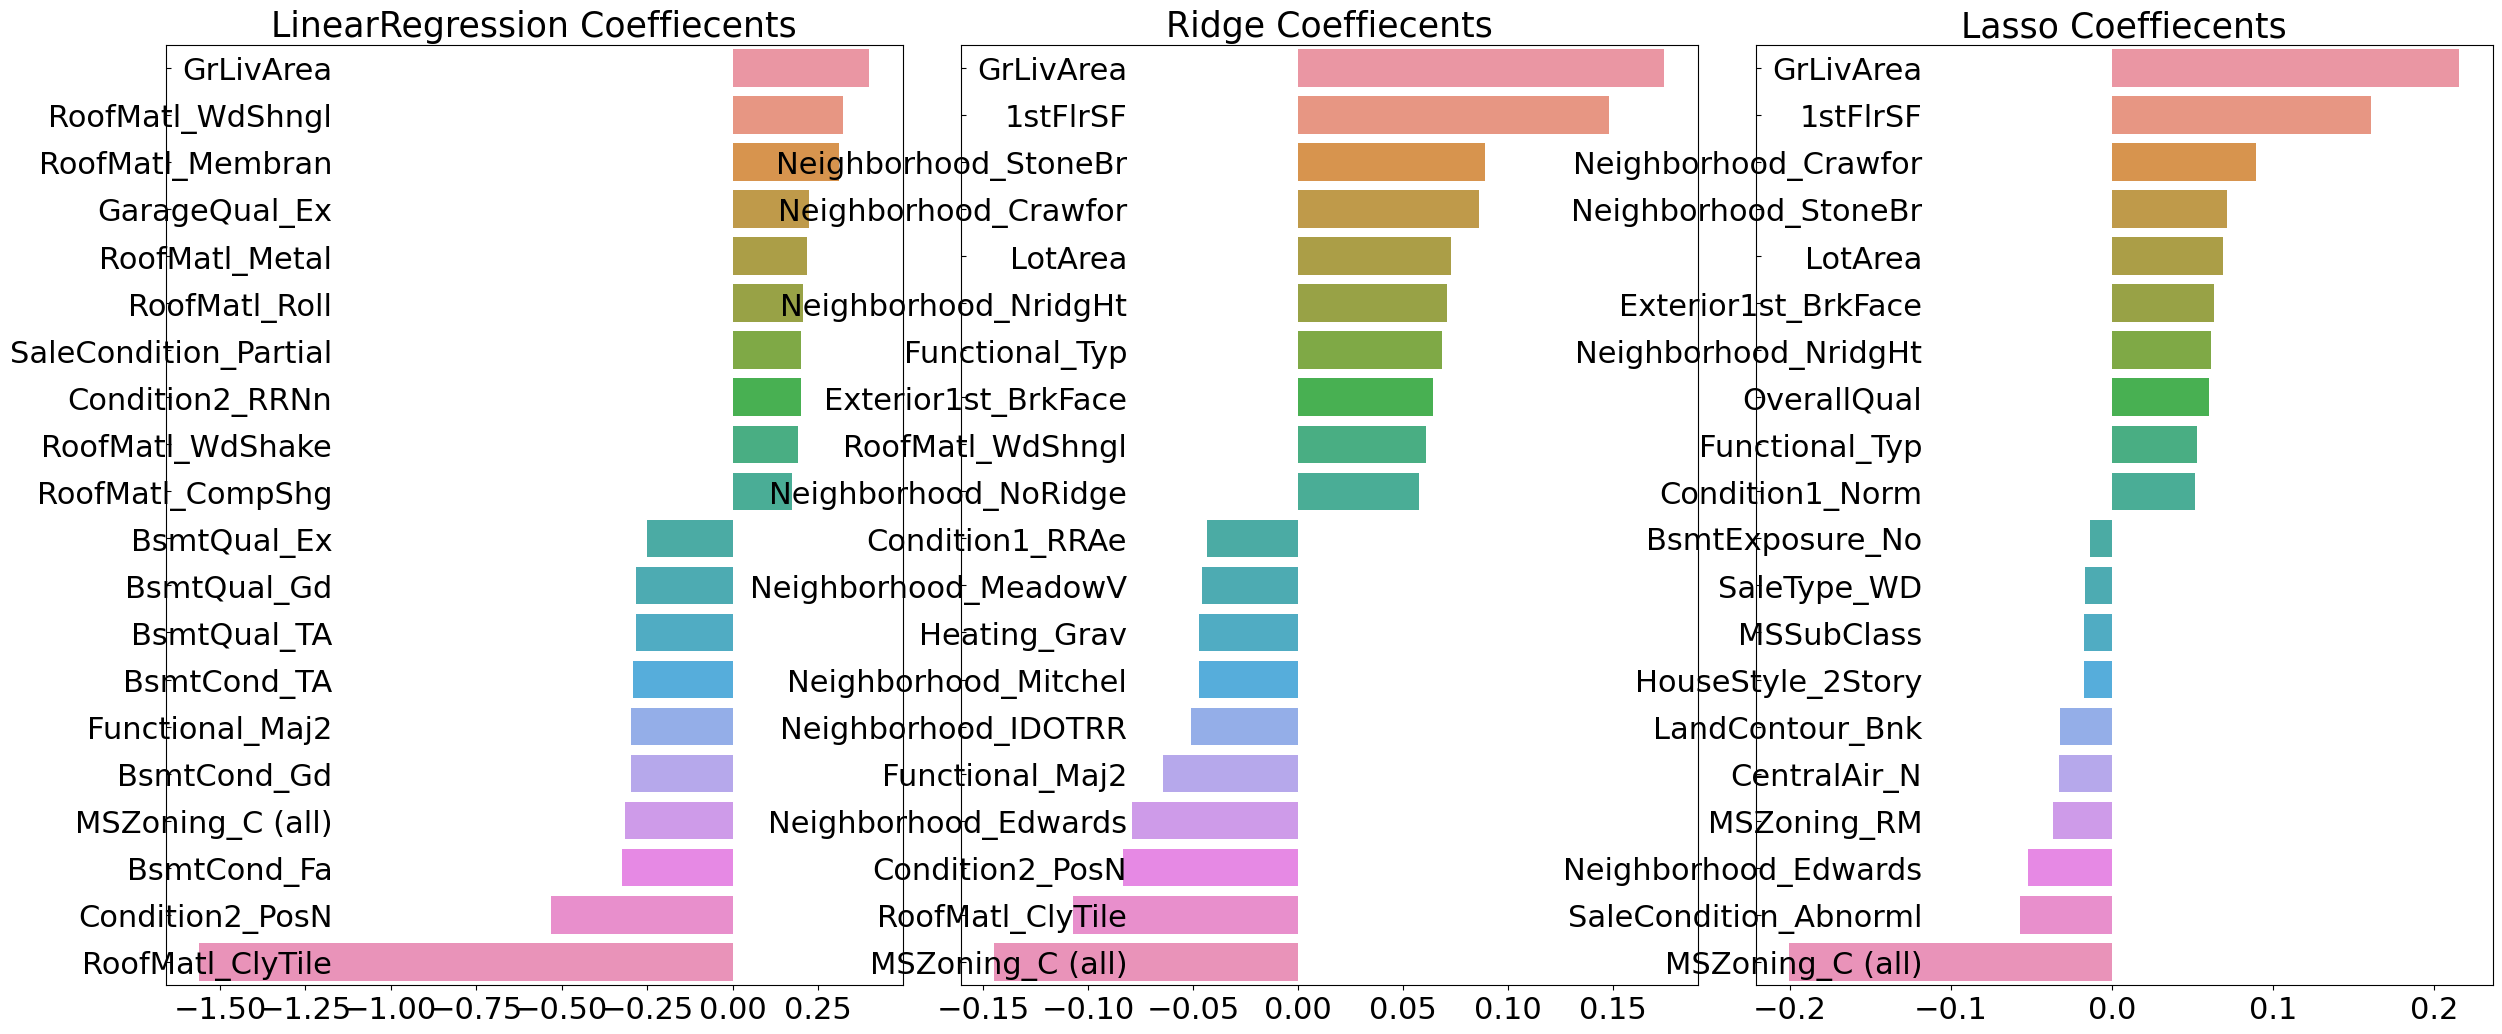

In [46]:
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha = 10)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha = 0.001)
lasso_reg.fit(X_train, y_train)

models = [lr_reg, best_ridge, best_lasso]
get_rmses(models)
visualize_coef(models)

<function matplotlib.pyplot.show(close=None, block=None)>

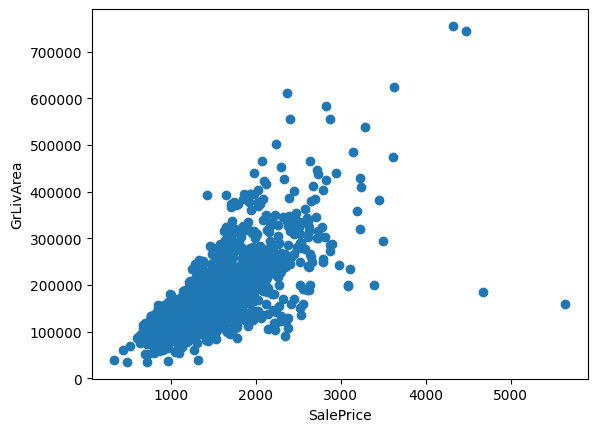

In [47]:
plt.scatter(x = df_org["GrLivArea"],y= df_org["SalePrice"])
plt.ylabel("GrLivArea")
plt.xlabel("SalePrice")
plt.show

In [48]:
cond1 = df_ohe["GarageArea"] > np.log1p(4000)
cond2 = df_ohe["SalePrice"] < np.log1p(500000)                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        
outliter_index = df_ohe[cond1 & cond2].index
print(outliter_index.values)
print(df_ohe.shape)
df_ohe.drop(outliter_index, axis= 0 , inplace= True)
print ( df_ohe.shape)

[   0    1    2 ... 1457 1458 1459]
(1460, 271)
(90, 271)


In [49]:
X_features = df_ohe.drop(columns=["SalePrice", "GarageArea"], errors="ignore")
y_target = df_ohe["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_target, test_size=0.2, random_state=156
)

ridge_params = { "alpha" : [0.05 , 0.1 , 1 ,5 ,8, 10, 12, 15 ,20]}
lasso_params = { "alpha" : [0.001, 0.005, 0.008, 0.03, 0.05, 0.1, 0.5, 1, 5]}

best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 0.2242 {'alpha': 5}
Lasso 0.2219 {'alpha': 0.008}


LinearRegression 0.251
Ridge 0.248
Lasso 0.287


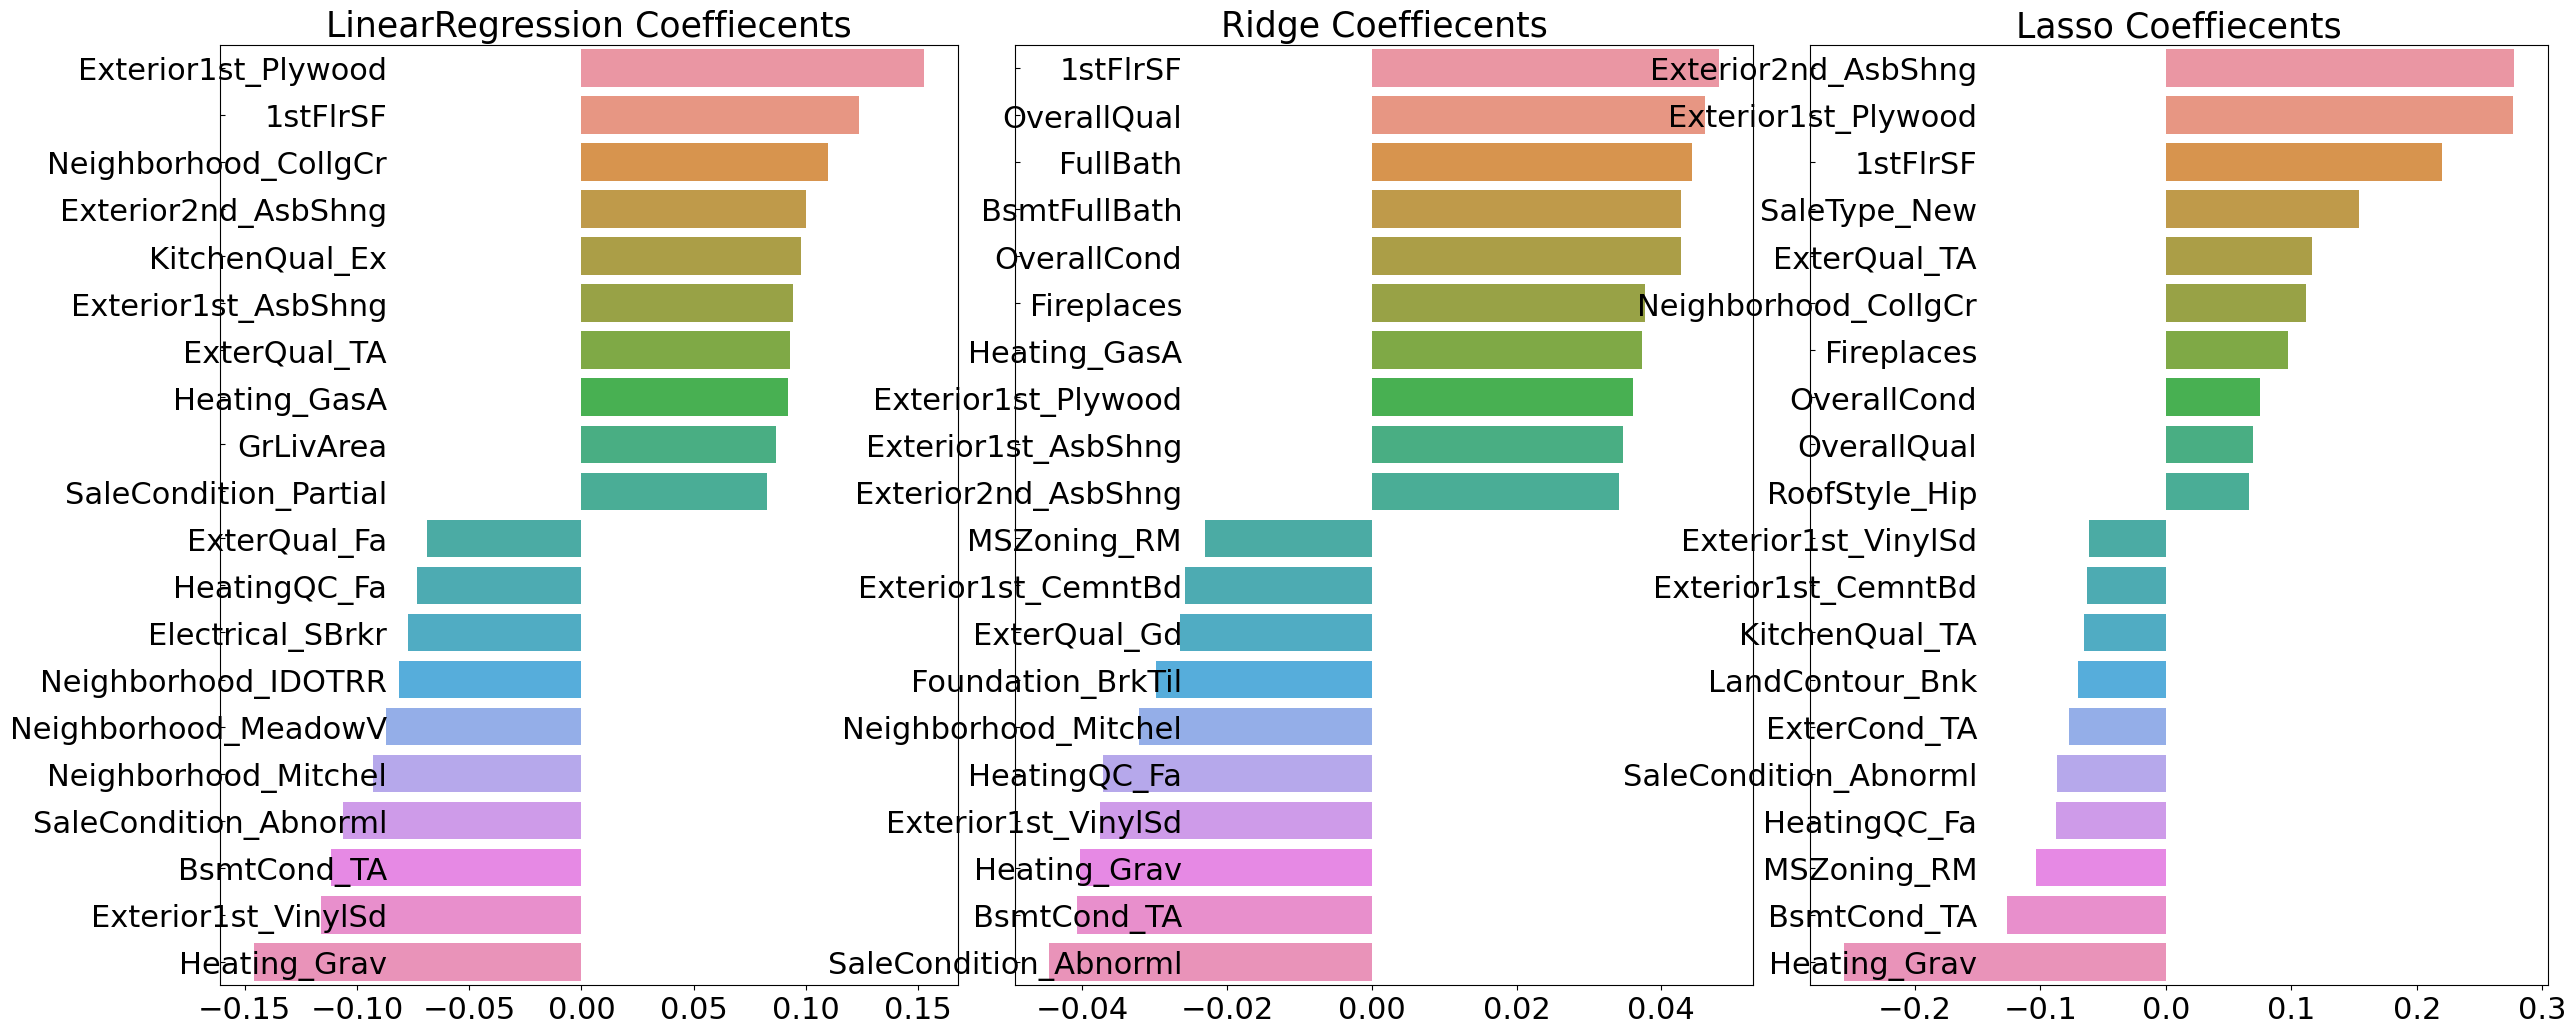

In [50]:
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha = 10)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha = 0.001)
lasso_reg.fit(X_train, y_train)

models = [lr_reg,ridge_reg,lasso_reg]

get_rmses(models)
visualize_coef(models)

In [51]:
from xgboost import XGBRegressor

xgb_params = {"n_estimator" : [1000]}
xgb_reg = XGBRegressor(n_estimators = 1000 , learing_rate = 0.05,
                       colsample_bytree = 0.5, subsample = 0.8)

best_xgb = print_best_params(xgb_reg,xgb_params)


[12:56:24] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "learing_rate", "n_estimator" } are not used.

[12:56:25] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "learing_rate", "n_estimator" } are not used.

[12:56:25] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "learing_rate", "n_estimator" } are not used.

[12:56:26] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "learing_rate", "n_estimator" } are not used.

[12:56:27] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windo

In [52]:
from lightgbm import LGBMRegressor

lgbm_parmas = {"n_estimator" : [1000]}
lgbm_reg = LGBMRegressor(n_estimators = 1000 , learning_rate= 0.05 , num_leaves = 4 , subsample = 0.6 , colsample_bytree= 0.4 , 
                         reg_lambda= 10 ,n_jobs = -1 , verdose = -1)

best_lgbm = print_best_params(lgbm_reg , lgbm_parmas)

[LightGBM] [Warning] Unknown parameter: verdose
[LightGBM] [Warning] Unknown parameter: n_estimator
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: verdose
[LightGBM] [Warning] Unknown parameter: n_estimator
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000185 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 312
[LightGBM] [Info] Number of data points in the train set: 72, number of used features: 35
[LightGBM] [Info] Start training from score 11.677278
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warni

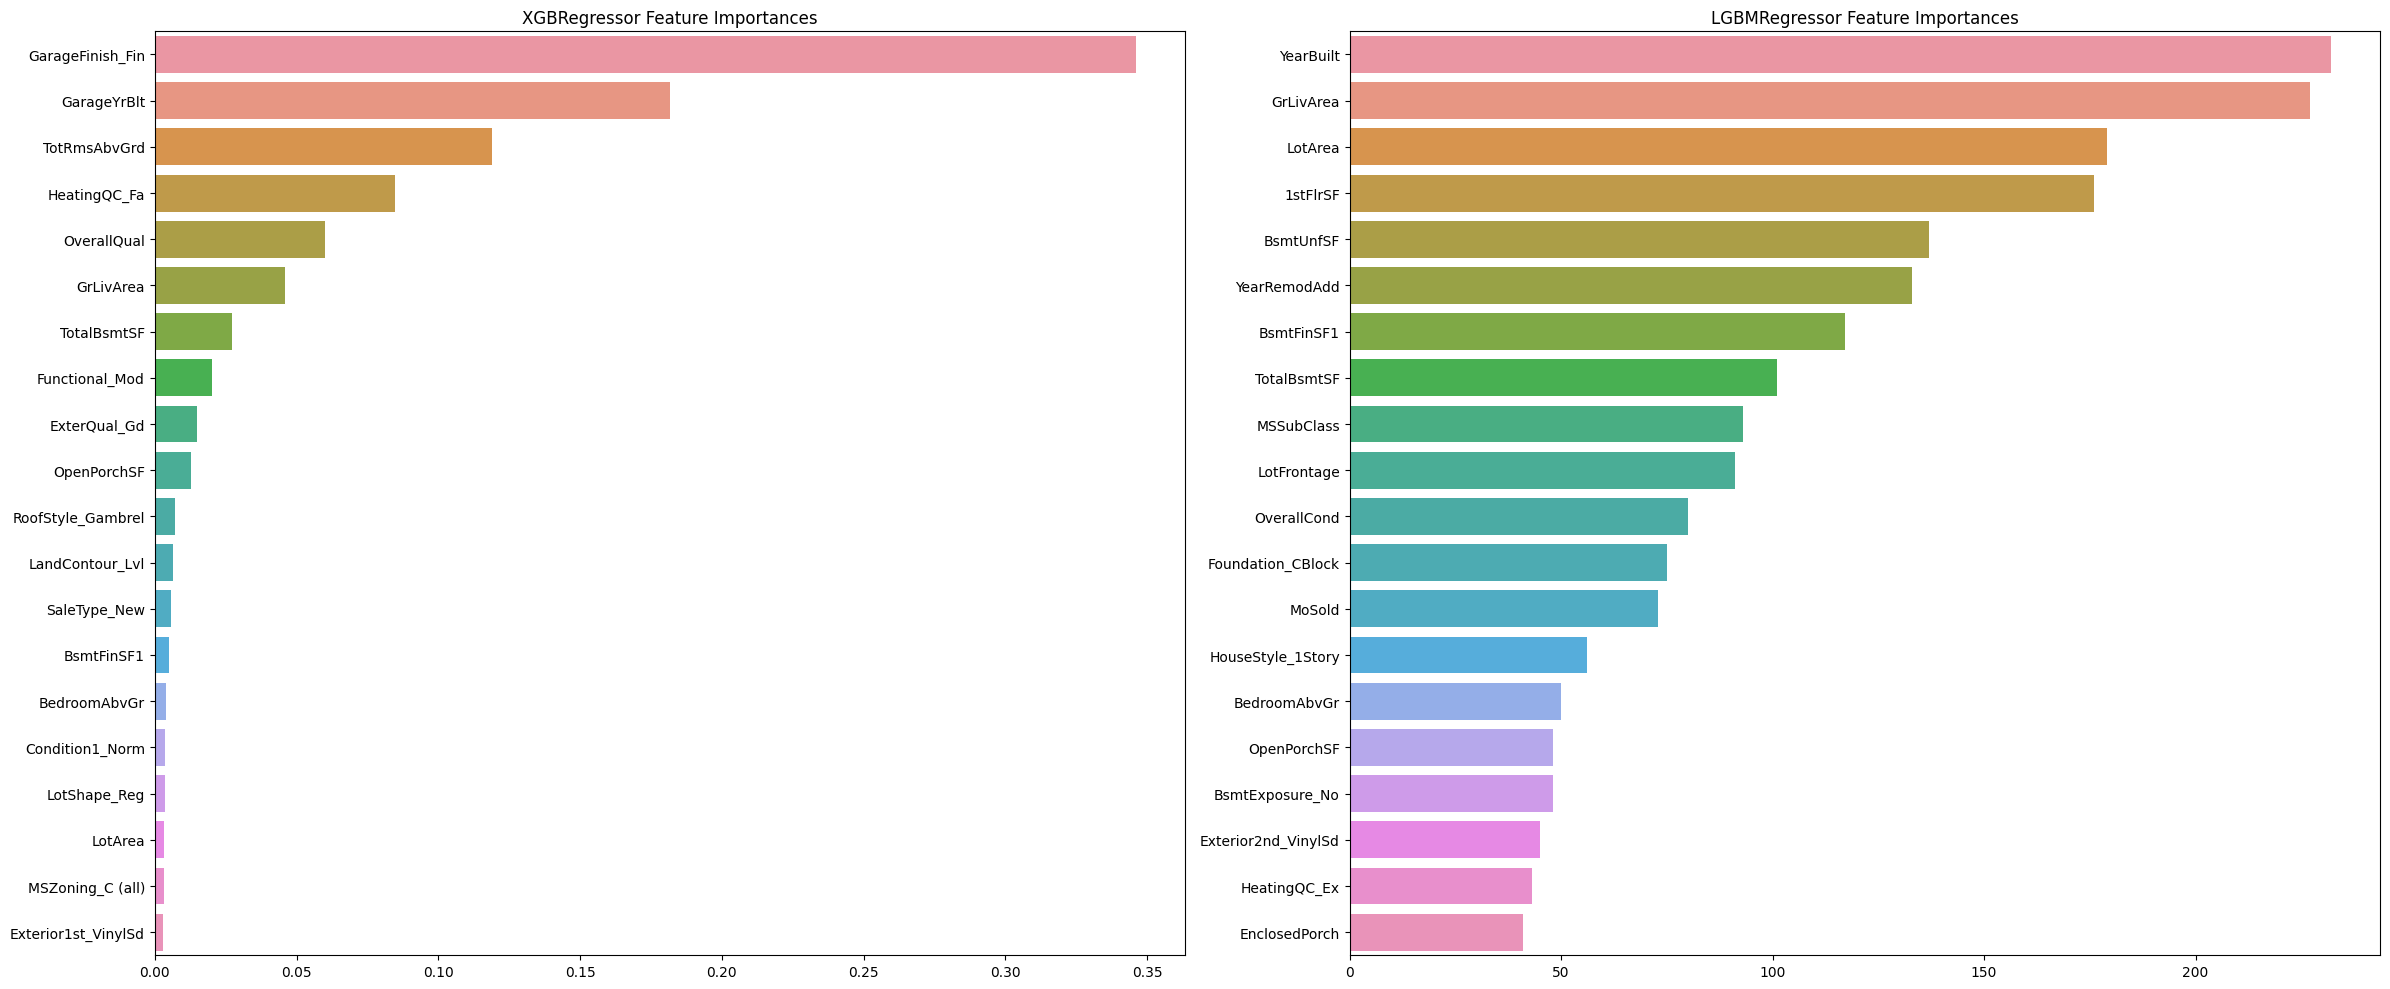

In [54]:
def get_top_features(model):
    ftr_importance = pd.Series(
        model.feature_importances_,
        index=X_features.columns
    )
    return ftr_importance.sort_values(ascending=False).head(20)


def visualize_ft_importances(models):
    fig, axs = plt.subplots(figsize=(24, 10), nrows=1, ncols=len(models))

    if len(models) == 1:
        axs = [axs]

    for ax, model in zip(axs, models):
        top_features = get_top_features(model)
        ax.set_title(f"{model.__class__.__name__} Feature Importances")
        sns.barplot(x=top_features.values, y=top_features.index, ax=ax)

    plt.tight_layout()
    plt.show()


models = [best_xgb, best_lgbm]
visualize_ft_importances(models)

In [55]:
def get_rmse_pred(preds):
    for key in preds.keys():
        pred_value = preds[key]
        mse = mean_squared_error(y_test, pred_value)
        rmse = np.sqrt(mse)
        print(key,rmse)

ridge_reg = Ridge(alpha= 8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha= 0.001)
lasso_reg.fit(X_train , y_train)


ridge_pred = ridge_reg.predict(X_test)
Lasso_pred = lasso_reg.predict(X_test)

pred = 0.4 * ridge_pred + 0.6 * Lasso_pred
preds = {"최종 혼합":pred , "Ridge" : ridge_pred, "Lasso" : Lasso_pred}
get_rmse_pred(preds)

최종 혼합 0.26191405063369566
Ridge 0.2472304189399386
Lasso 0.2868703304099603


In [56]:
xgb_reg = XGBRegressor(n_estimators = 1000, learning_rate = 0.05, colsample_bytree = 0.5 , subsample = 0.8)

lgbm_reg = LGBMRegressor(n_estimators= 1000 , learning_rate= 0.05 , num_leaves= 4 , subsample= 0.6 ,
                          colsample_bytree= 0.4 , reg_lambda= 10 , n_jobs = -1 , verdose = -1)

xgb_reg.fit(X_train , y_train)
lgbm_reg.fit(X_train , y_train)
xgb_pred = xgb_reg.predict(X_test)
lgbm_pred = lgbm_reg.predict(X_test)

pred = 0.5 * xgb_pred + 0.5 * lgbm_pred
print(pred[:20])
preds = {"최종혼합" : pred , "XGB" : xgb_pred, "LGBM" : lgbm_pred}

get_rmse_pred(preds)

[LightGBM] [Warning] Unknown parameter: verdose
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: verdose
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000151 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 306
[LightGBM] [Info] Number of data points in the train set: 72, number of used features: 33
[LightGBM] [Info] Start training from score 11.715998
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

def get_stacking_base_datasets ( models, X_train, y_train_y , X_test_n, n_folds):
    kf = KFold(n_splits= n_folds, shuffle= False)
    train_fold_pred = np.zeros((X_train_n.shape[0],n_folds))
    test_pred = np.zeros(X_test_n.shape[0], n_folds)
    print(model.__class__.__name__, "model시작")

    for folder_counter(train_index, vaild_index) in enumerate(kf.split(X_train_n)):
    print("폴더 세트" ,folder_counter, "시작")
        X_tr = X_train_n[train_index]
        y_tr = y_train_y[train_index]
        X_tr = X_train_n [ valid_index]
        model.fit(X_tr , y_tr)
        train_fold_pred[valid_index , :] = model.predict(X_te).reshape(-1 , 1)
        test_pred[: , folder_counter] = model.predict(X_test_n)

    test_pred_mean = np.mean(test_pred, axis = 1).reshape(-1,1)
    return train_fold_pred, test_pred_mean

In [ ]:
X_train_n = X_train.values
X_test_n = X_test.values
y_train_n = y_train.values
ridge_train, ridge_test = get_stacking_base_datasets(
    ridge_reg, X_train_n, y_train_n, X_test_n, 5
)
lasso_train, lasso_test = get_stacking_base_datasets(
    lasso_reg, X_train_n, y_train_n, X_test_n, 5
)
xgb_train, xgb_test = get_stacking_base_datasets(
    xgb_reg, X_train_n, y_train_n, X_test_n, 5
)
lgbm_train, lgbm_test = get_stacking_base_datasets(
    lgbm_reg, X_train_n, y_train_n, X_test_n, 5
)

NameError: name 'get_stacking_base_datasets' is not defined

In [ ]:
Stack_final_X_train = np.concatenate((ridge_train , lasso_train , xgb_train , lgbm_train), axis = 1)
Stack_final_X_test = np.concatenate((ridge_train , lasso_test , xgb_test , lgbm_test), axis = 1)

meta_model_lasso = Lasso(alpha = 0.0005)
meta_model_lasso.fit(Stack_final_X_train, y_train)
final = meta_model_lasso.predict(Stack_final_X_test)
mse = mean_squared_error(y_test, final)
rmse = np.sqrt(mse)
print("스태킹 최종 rmse",rmse)

NameError: name 'ridge_train' is not defined

In [ ]:
from sklearn.preprocessing import StandardScaler

iris

In [ ]:
me